![Banner](../images/09_04_banner_rs_uav.png)


# Photogrammetry: Orthomosaic, DSM and DTM

Structure-from-Motion (SfM) photogrammetry turns overlapping frames into three map products:
an **orthomosaic** (a geometrically corrected image), a **digital surface model** (DSM, the
top of everything, canopy included) and a **digital terrain model** (DTM, bare ground).


## Overview

The difference between the surface and the bare ground is the canopy height model (CHM). This notebook explains the SfM steps on real LUMS frames, shows how to run OpenDroneMap (ODM) from Python with `rs.uav.run_docker` and `rs.uav.run_nodeodm`, and loads finished products with `rs.uav.load_outputs`, whether they come from ODM or from commercial software such as Agisoft Metashape (used in the LUMS paper).


## Core concepts

### Learning objectives

1. Describe the SfM pipeline: features, matching, bundle adjustment, dense cloud, DEM, ortho.
2. See, on real frames, why overlap controls whether images can be matched.
3. Contrast GCP / RTK workflows with the infrastructure-free workflow of the LUMS study.
4. Configure and launch OpenDroneMap from Python (Docker or a NodeODM server).
5. Load orthomosaic, DSM and DTM from ODM or Metashape exports and derive a CHM.

### Data

| Data | Type |
|---|---|
| LUMS rice frames, 22 Aug 2025 (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping/2025-08-22`) | **Real** (CC BY 4.0) |
| Full 13 Aug 2025 orthomosaic (Google Drive; set `ORTHO_PATH` if you have it) | **Real**, optional |
| Small example orthomosaic, DSM and DTM written when the full mosaic is absent | **Simulated** |

### Contents

1. Setup
2. The SfM pipeline
3. Features and matching on real frames
4. Ground control: GCP / RTK vs infrastructure-free
5. Running OpenDroneMap from Python
6. Loading products: ODM layout or explicit paths
7. Canopy height from DSM - DTM
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

import shutil  # look for the docker executable
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
import cv2  # OpenCV: features and warping

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")
LUMS = DATA / "infrastructure-free-uav-phenotyping"
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

RUN_ODM = False  # set True to run OpenDroneMap (needs Docker or a NodeODM server)
ORTHO_PATH = None  # e.g. "../../../../Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping/2025-08-13/ortho.tif" after download
print("docker available:", shutil.which("docker") is not None)

docker available: False


## The SfM pipeline

| Step | What happens | What can go wrong |
|---|---|---|
| 1. Feature detection | Thousands of distinctive points (SIFT, ORB) per image | Few features over uniform water or soil |
| 2. Matching | Same points found in overlapping images; outliers removed with RANSAC | Low overlap, repeated texture (crop rows), wind-moved leaves |
| 3. Bundle adjustment | Camera positions, orientations and lens model solved together with 3-D points | Lens model and camera height trade off: doming |
| 4. Georeferencing | Model scaled and placed with GPS tags, GCPs or RTK | Consumer GPS: metres of absolute error |
| 5. Dense matching | Depth for nearly every pixel: dense point cloud | Thin leaves, moving canopy |
| 6. DSM / DTM | Highest (DSM) or ground-classified (DTM) points gridded | Ground hidden under full canopy |
| 7. Orthomosaic | Images projected onto the DSM and blended | Seams, ghosting on tall plants |

Steps 1 and 2 can be demonstrated directly on the data.


## Features and matching on real frames

The public LUMS sample frames were picked from different parts of the field, so no two of them
overlap. To see matching at work, the cell below makes two "views" from one frame: a left
window and a right window that share a chosen fraction of their width, with the second view
slightly rotated and rescaled as a drone would see it on the next pass. ORB features are then
matched and a homography is fitted with RANSAC using `rs.uav.estimate_homography`.


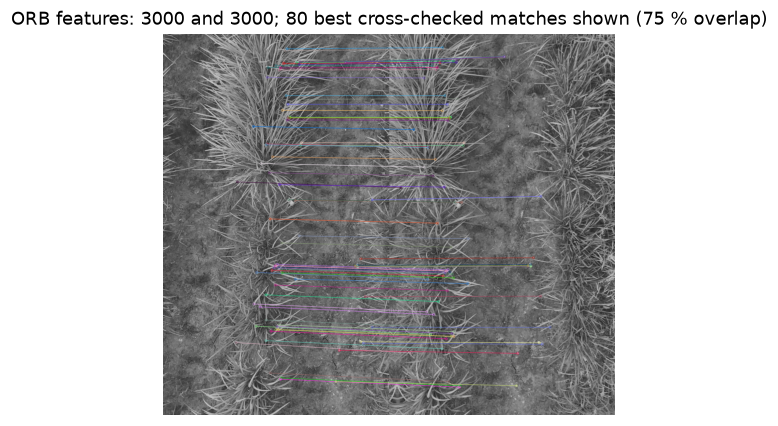

In [2]:
frame = rs.uav.to_rgb_array(rs.uav.read_frame(sorted((LUMS / "2025-08-22").glob("*.png"))[0], max_dim=1920))
gray = cv2.cvtColor((frame * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
H_img, W_img = gray.shape

def two_views(img, overlap, width=640, angle=4.0, scale=1.03):
    """Two windows of `width` px sharing `overlap` of their width; the second rotated/scaled."""
    shift_px = int(round(width * (1 - overlap)))
    x0 = (img.shape[1] - width - shift_px) // 2
    a = img[:, x0:x0 + width]
    b_full = img[:, x0 + shift_px:x0 + shift_px + width]
    M = cv2.getRotationMatrix2D((width / 2, img.shape[0] / 2), angle, scale)
    b = cv2.warpAffine(b_full, M, (width, img.shape[0]), borderMode=cv2.BORDER_REFLECT)
    return a, b

a, b = two_views(gray, 0.75)
orb = cv2.ORB_create(3000)
ka, da = orb.detectAndCompute(a, None); kb, db = orb.detectAndCompute(b, None)
m = sorted(cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(da, db), key=lambda x: x.distance)[:80]
vis = cv2.drawMatches(a, ka, b, kb, m, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(12, 4.5)); plt.imshow(vis); plt.axis("off")
plt.title(f"ORB features: {len(ka)} and {len(kb)}; 80 best cross-checked matches shown (75 % overlap)")
plt.show()

Now vary the overlap. The number of RANSAC inliers (matches consistent with one geometric
model) collapses as overlap falls, which is why mapping missions plan 75 to 85 % forward
overlap.


,overlap_%,matches,inliers,rmse_px
0,90,1488,1440,1.03
1,80,1264,1218,1.06
2,70,946,918,1.04
3,60,657,633,1.10
4,50,413,392,1.05
5,40,238,226,1.00
6,30,102,94,0.79
7,20,15,7,0.70


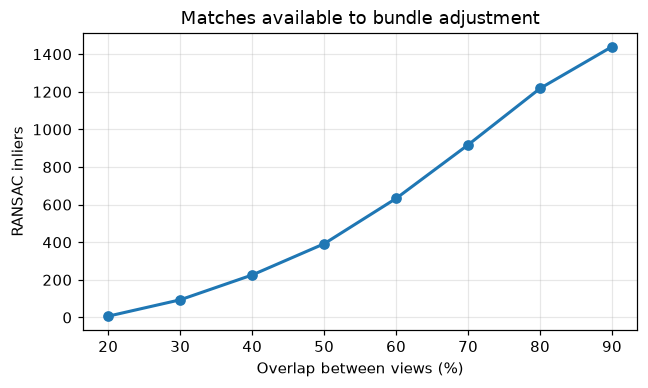

In [3]:
rows = []
for ov in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]:
    a, b = two_views(gray, ov)
    try:
        _, info = rs.uav.estimate_homography(b, a, method="orb", n_features=3000)
    except RuntimeError as e:  # too few matches
        info = {"matches": 0, "inliers": 0, "rmse_px": np.nan}
    rows.append({"overlap_%": int(ov * 100), **{k: info[k] for k in ("matches", "inliers", "rmse_px")}})
ov_tab = pd.DataFrame(rows)
display(ov_tab.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(ov_tab["overlap_%"], ov_tab.inliers, "o-", lw=2)
ax.set(xlabel="Overlap between views (%)", ylabel="RANSAC inliers", title="Matches available to bundle adjustment")
ax.grid(alpha=0.3); plt.show()

Repeated texture is the other enemy: rice rows look alike everywhere, so a feature can match
the wrong row. Lowe's ratio test (used inside `estimate_homography`) rejects a match when the
second-best candidate is almost as good as the best one, and RANSAC removes the rest.


## Ground control: GCP / RTK vs infrastructure-free

| Approach | Absolute accuracy | Cost and effort | Typical artefact |
|---|---|---|---|
| GCPs surveyed with GNSS | 1-3 cm | Targets laid and surveyed every flight | Little doming if GCPs cover the area |
| RTK / PPK drone | 2-5 cm | RTK drone and base or correction service | Little doming |
| Consumer GPS only (LUMS) | metres | None | Doming / bowl and tilt in the DEM |

The LUMS study used no GCPs and no RTK. Its orthomosaics are therefore internally consistent
but not accurately placed on Earth, and its elevation models carried a dome-shaped error that
was removed afterwards with RANSAC plane/polynomial fitting (notebook 09_04_06). For
**relative** traits within a field (counts, cover, height above local ground) this is enough.


## Running OpenDroneMap from Python

ODM is the open alternative to Agisoft Metashape and Pix4D. GeoLattice drives it two ways:

* `rs.uav.run_docker(project_dir, options=...)` runs the `opendronemap/odm` image on
  `project_dir/images` and writes the products into `project_dir`.
* `rs.uav.run_nodeodm(images, out_dir, host=..., port=...)` sends images to a NodeODM server
  (`docker run -p 3000:3000 opendronemap/nodeodm`), waits and downloads the results. Needs
  `pip install pyodm`.

The options mirror ODM's command-line flags. For the LUMS 6 m frames a sensible start is:


In [4]:
odm_options = {
    "dsm": True, "dtm": True,               # build both elevation models
    "orthophoto-resolution": 0.2,           # cm/px; about the frame GSD at 6 m
    "dem-resolution": 0.6,                  # cm/px; DEMs are noisier, so coarser
    "feature-quality": "high",
    "pc-quality": "high",
    "matcher-neighbors": 16,                # video frames: many close neighbours
    "use-3dmesh": False,                    # 2.5-D mesh is better for flat fields
    "auto-boundary": True,
}
pd.Series(odm_options, name="value").to_frame()

,value
dsm,True
dtm,True
orthophoto-resolution,0.2
dem-resolution,0.6
feature-quality,high
pc-quality,high
matcher-neighbors,16
use-3dmesh,False
auto-boundary,True


In [5]:
project = OUT / "odm_lums_0822"
if RUN_ODM:
    imgs = project / "images"; imgs.mkdir(parents=True, exist_ok=True)
    for f in sorted((LUMS / "2025-08-22").glob("*.png")):  # replace with an overlapping frame sequence
        shutil.copy(f, imgs / f.name)
    if shutil.which("docker"):
        rs.uav.run_docker(project, options=odm_options, gpu=False)
    else:
        rs.uav.run_nodeodm(sorted(imgs.glob("*.png")), project, host="localhost", port=3000, options=odm_options)
else:
    print("RUN_ODM is False: skipping photogrammetry. The 10 public frames per date do not overlap,")
    print("so a real run needs an overlapping sequence (e.g. frames from rs.uav.extract_frames).")

RUN_ODM is False: skipping photogrammetry. The 10 public frames per date do not overlap,
so a real run needs an overlapping sequence (e.g. frames from rs.uav.extract_frames).


Expect ODM to need several GB of RAM per hundred 4K frames and tens of minutes on a laptop
CPU; `gpu=True` uses the `opendronemap/odm:gpu` image for feature extraction.


## Loading products: ODM layout or explicit paths

`rs.uav.load_outputs(odm_dir)` looks for `odm_orthophoto/odm_orthophoto.tif`,
`odm_dem/dsm.tif` and `odm_dem/dtm.tif`. Metashape and Pix4D use other names, so explicit
paths can be given instead (or in addition).

So that this section runs without a photogrammetry run, the cell below writes a small set of
example products: an orthomosaic made from a LUMS frame, placed in UTM zone 43N at the LUMS
field with 1.85 mm pixels, and a DSM/DTM pair built with `rs.uav.synthetic_dem`, which adds a
realistic GCP-free dome and tilt. The DTM is written on a **shifted grid of the same size**,
as happens when two products come from different exports.


In [6]:
import rioxarray  # noqa: F401  (registers the .rio accessor)
from affine import Affine

crs = "EPSG:32643"  # WGS 84 / UTM 43N (Lahore)
x0, y0 = 437_000.0, 3_481_500.0  # an easting/northing near the LUMS campus (illustrative)

ortho = rs.uav.read_frame(sorted((LUMS / "2025-08-22").glob("*.png"))[0], max_dim=1920)
gsd_o = 0.00185 * 3840 / ortho.sizes["x"]  # GSD after downsizing
ortho = ortho.assign_coords(x=x0 + gsd_o * (np.arange(ortho.sizes["x"]) + 0.5),
                            y=y0 - gsd_o * (np.arange(ortho.sizes["y"]) + 0.5)).rio.write_crs(crs)
ortho_path = OUT / "example_ortho.tif"
ortho.rio.to_raster(ortho_path)

big_dsm, big_chm = rs.uav.synthetic_dem((184, 326), gsd=0.02, doming=0.8, canopy_height=0.5, seed=3)
ground = big_dsm - big_chm  # true (domed) ground surface on the large grid

def place(da):
    """Give a local-grid DataArray UTM coordinates."""
    return da.assign_coords(x=x0 + da.x.values, y=y0 + da.y.values).rio.write_crs(crs)

dsm = place(big_dsm.isel(y=slice(0, 180), x=slice(0, 320)))          # DSM export grid
chm_true = big_chm.isel(y=slice(0, 180), x=slice(0, 320)).values      # truth on the DSM grid
dtm = place(ground.isel(y=slice(2, 182), x=slice(3, 323)))            # DTM export: same size, 3 x 2 px offset
dsm_path, dtm_path = OUT / "example_dsm.tif", OUT / "example_dtm.tif"
dsm.rio.to_raster(dsm_path); dtm.rio.to_raster(dtm_path)
print("DSM origin", float(dsm.x[0]), float(dsm.y[0]), "| DTM origin", float(dtm.x[0]), float(dtm.y[0]))
print("wrote", ortho_path, dsm_path, dtm_path)

DSM origin 437000.01 3481499.99 | DTM origin 437000.07 3481499.95
wrote outputs/example_ortho.tif outputs/example_dsm.tif outputs/example_dtm.tif


In [7]:
src = ORTHO_PATH or ortho_path
products = rs.uav.load_outputs(orthophoto=src, dsm=dsm_path, dtm=dtm_path)
for k, v in products.items():
    print(f"{k:11s}", dict(v.sizes), "res", np.round(v.rio.resolution(), 4), v.rio.crs)

orthophoto  {'band': 3, 'y': 1080, 'x': 1920} res [ 0.0037 -0.0037] EPSG:32643
dsm         {'band': 1, 'y': 180, 'x': 320} res [ 0.02 -0.02] EPSG:32643
dtm         {'band': 1, 'y': 180, 'x': 320} res [ 0.02 -0.02] EPSG:32643


## Canopy height from DSM - DTM

`rs.uav.chm_from_surfaces` checks CRS **and** grid alignment (not just the shape) and
reprojects the DTM onto the DSM grid when they differ. Subtracting the raw arrays of the
shifted pair would mix pixels 6 cm apart.


,method,RMSE_m
0,raw array difference,0.031
1,chm_from_surfaces,0.000


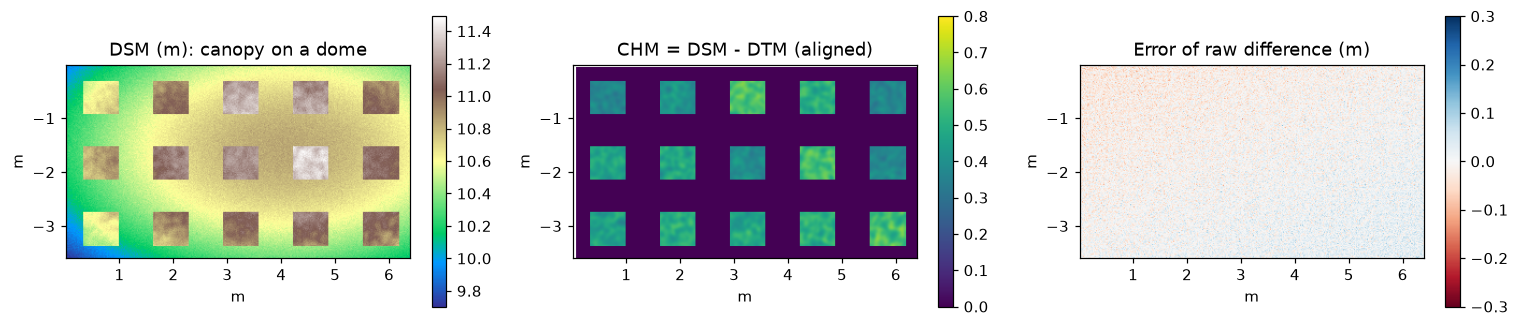

In [8]:
dsm_r, dtm_r = products["dsm"], products["dtm"]
naive = dsm_r.squeeze().values - dtm_r.squeeze().values  # wrong: ignores the offset
chm = rs.uav.chm_from_surfaces(dsm_r, dtm_r, min_height=0.0)
truth = chm_true
inner = (slice(4, -4), slice(4, -4))  # skip the border the DTM does not cover
err = pd.DataFrame({
    "method": ["raw array difference", "chm_from_surfaces"],
    "RMSE_m": [np.sqrt(np.nanmean((naive - truth)[inner] ** 2)),
               np.sqrt(np.nanmean((chm.values - truth)[inner] ** 2))],
})
display(err.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ext = [float(dsm_r.x.min()) - x0, float(dsm_r.x.max()) - x0, float(dsm_r.y.min()) - y0, float(dsm_r.y.max()) - y0]
im0 = axes[0].imshow(dsm_r.squeeze(), cmap="terrain", extent=ext); axes[0].set_title("DSM (m): canopy on a dome")
im1 = axes[1].imshow(chm, cmap="viridis", vmin=0, vmax=0.8, extent=ext); axes[1].set_title("CHM = DSM - DTM (aligned)")
im2 = axes[2].imshow(naive - truth, cmap="RdBu", vmin=-0.3, vmax=0.3, extent=ext); axes[2].set_title("Error of raw difference (m)")
for ax, im in zip(axes, [im0, im1, im2]):
    plt.colorbar(im, ax=ax, shrink=0.8); ax.set(xlabel="m", ylabel="m")
plt.tight_layout(); plt.show()

Two points stand out. First, the DSM is dominated by the dome, not the crop: notebook
09_04_06 removes it when no DTM exists. Second, an alignment error of a few centimetres
shows up as bands of false height along every plot edge and a tilt-like bias wherever the
ground slopes. Here alignment recovers the true heights exactly because the offset is a whole
number of pixels; sub-pixel offsets leave a small interpolation error.


## Summary and exercises

**Key points**

- Structure-from-Motion matches features across overlapping frames, solves the cameras, and
  builds a dense cloud, a DEM and an orthomosaic.
- Overlap decides whether neighbouring frames match. GCP or RTK fixes where the model sits
  on the ground.
- `run_docker` and `run_nodeodm` launch OpenDroneMap. `load_outputs` opens an orthomosaic,
  DSM and DTM from ODM or from a Metashape export.
- Canopy height is DSM minus DTM (`chm_from_surfaces`).

**GeoLattice functions used:** `rs.uav.estimate_homography`, `rs.uav.run_docker`, `rs.uav.run_nodeodm`,
`rs.uav.load_outputs`, `rs.uav.chm_from_surfaces`, `rs.uav.synthetic_dem`.

**Exercises**

1. Repeat the overlap experiment with `method="sift"`. Does SIFT keep more inliers at 40 %?
2. Increase `angle` in `two_views` to 20°. At what angle does matching fail at 75 % overlap?
3. Download the 2025-08-13 orthomosaic, set `ORTHO_PATH` and reload. What is its resolution
   and does it carry a CRS?
4. Shift the example DTM by a full 0.5 m and compare the two CHM RMSEs again.

**References**

- Westoby, M. J. et al. (2012). 'Structure-from-Motion' photogrammetry: a low-cost, effective
  tool for geoscience applications. *Geomorphology*, 179, 300-314.
- OpenDroneMap Authors. ODM: a command line toolkit to generate maps, point clouds, 3D models
  and DEMs from drone images. https://opendronemap.org
- Chaudhry, H., Rana, S. and Jaleel, A. (2026). *Computers and Electronics in Agriculture*
  (accepted).
